# Predicting total spend: tuning Linear + Random Forest
**Timothy Hsu**

Goal: predict `total_spend` before a campaign runs (brief: R² above 0.55, MAPE under 30%).

Data: Abhiram's split in `data/spend_train_val_split/` -> 332 older campaigns to train, 82 newer ones to validate, 72 columns.

Steps: re-run Abhiram's + Bakari's spend models on the same split -> tune the linear model and the Random Forest -> compare everything in one results table.

## What the team found so far

| Notebook | Model | R² | MAPE | Takeaway |
|---|---|---|---|---|
| AbhiramSegu_Total_Spend_Model | Ridge on log spend, 14 columns | 0.42 | 106.5% | target list + product + size works best; more inputs -> worse CV |
| BakariKerr_TS_Tree_Models | Random Forest on log spend | 0.56 | 106.8% | best so far; log spend >> raw spend (raw RF R² 0.06) |
| BakariKerr_TS_Tree_Models | XGBoost on log spend | 0.42 | 124.7% | behind the RF |
| BakariKerr_TS_NN_Test | small neural net (mean of 3 seeds) | −0.06 | 214% | worse than the trees, changes a lot by seed |

`target_list` is the top driver in both Abhiram's correlations and Bakari's importance plots. Nobody is close to 30% MAPE yet.

Experiments here:
- E0: baselines
- E1: re-run Abhiram's Ridge + Bakari's RF and XGBoost
- E2: tune the linear model's penalty (Abhiram's 14 columns)
- E3: same, but also let tuning pick the inputs (for fun)
- E4: tune the Random Forest (Bakari's 72 columns)

XGBoost is re-run as a reference but not tuned. The neural net isn't re-run (needs PyTorch, and it was already behind the trees).

In [1]:
%pip install -q pandas numpy scikit-learn xgboost optuna matplotlib

## Setup

In [2]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from IPython.display import display
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, RidgeCV, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor

SEED = 42
N_FOLDS = 4                                                             # CV folds, oldest -> newest
TRIALS = {"Linear": 100, "Linear + inputs": 200, "Random Forest": 150}  # Optuna tries per search
GOAL = {"R2": 0.55, "MAPE (%)": 30}                                     # brief's goal for spend
MAPE_MIN_SPEND = 1000                                                   # team rule: MAPE only counts spend >= $1k

BLUE, GRAY, INK = "#2a78d6", "#8a8984", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110})
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

## 1. Load the data

`y` is raw `total_spend` -> take `np.log1p` to model log spend. The files only keep the start year + month, but that's enough to put campaigns in time order for CV.

In [3]:
data_dir = Path("data/spend_train_val_split")
if not data_dir.exists():
    data_dir = Path("../data/spend_train_val_split")   # if run from notebooks/

X_train = pd.read_csv(data_dir / "X_train.csv")
X_val = pd.read_csv(data_dir / "X_val.csv")
y_train = pd.read_csv(data_dir / "y_train.csv")["total_spend"]
y_val = pd.read_csv(data_dir / "y_val.csv")["total_spend"]
assert X_train.columns.equals(X_val.columns)
log_y_train = np.log1p(y_train)

# Months since year 0 -> used to sort campaigns by date for CV
month_train = (X_train["start_year"] * 12 + X_train["start_month"] - 1).to_numpy()

def month_name(m):
    return f"{m // 12}-{m % 12 + 1:02d}"

print("Training rows:", len(X_train), f"({month_name(month_train.min())} to {month_name(month_train.max())})")
print("Validation rows:", len(X_val))
print("Input columns:", X_train.shape[1])

Training rows: 332 (2020-12 to 2025-03)
Validation rows: 82
Input columns: 72


### Input groups

72 columns = 8 inputs (grouped the same way as Abhiram). I added 2 extra inputs for the linear model only, so tuning can try them:
- `target_list_sq`: log target list squared -> lets spend curve with list size
- `target_list_x_product`: log target list × each product -> each product gets its own slope

In [4]:
# Group the 72 columns back into the inputs they came from
groups = {"target_list": ["log_target_list"], "date": ["start_year", "start_month"]}
for name in ["sub_product_name", "campaign_size", "company", "country", "npi_specialty", "region"]:
    groups[name] = [c for c in X_train.columns if c.startswith(name + "_")]

# Extra inputs for the linear model, centered on the training mean
center = X_train["log_target_list"].mean()

def add_extras(X):
    X = X.copy()
    target_list = X["log_target_list"] - center
    X["target_list_sq"] = target_list ** 2
    for c in groups["sub_product_name"]:
        X["tl_x_" + c] = target_list * X[c]
    return X

XL_train = add_extras(X_train)
XL_val = add_extras(X_val)
groups["target_list_sq"] = ["target_list_sq"]
groups["target_list_x_product"] = ["tl_x_" + c for c in groups["sub_product_name"]]

pd.Series({name: len(cols) for name, cols in groups.items()}, name="columns").rename_axis("input").to_frame()

,columns
input,
target_list,1
date,2
sub_product_name,10
campaign_size,3
company,28
country,8
npi_specialty,12
region,8
target_list_sq,1


## 2. Scoring

Same scoring as Abhiram + Bakari: predict log spend -> convert back to $ -> negatives set to 0. MAPE only uses campaigns with spend >= $1k. "Typical factor off" = how many times too high/low the median prediction is.

In [5]:
def evaluate(actual, pred):
    actual = np.asarray(actual, dtype=float)
    pred = np.maximum(np.asarray(pred, dtype=float), 0)
    scored = actual >= MAPE_MIN_SPEND
    a, p = actual[scored], pred[scored]
    factor_off = np.full(len(a), np.inf)
    factor_off[p > 0] = np.maximum(p[p > 0] / a[p > 0], a[p > 0] / p[p > 0])
    return {"R2": r2_score(actual, pred),
            "log R2": r2_score(np.log1p(actual), np.log1p(pred)),
            "MAPE (%)": (np.abs(a - p) / a).mean() * 100,
            "typical factor off": np.median(factor_off),
            "within 2x (%)": (factor_off <= 2).mean() * 100}

# Every experiment gets logged here -> one results table at the end
results, predictions = {}, {}

def record(name, pred):
    predictions[name] = np.maximum(np.asarray(pred, dtype=float), 0)
    results[name] = evaluate(y_val, pred)

def score():
    return pd.DataFrame(results).T.rename_axis("model").round(2)

## E0 + E1: baselines and teammates' models

Same settings as their notebooks. Ridge + XGBoost match their results exactly. RF MAPE is 107.0% here vs 106.8% in Bakari's run (small difference between machines).

In [6]:
# E0: baselines (overall median, median per product)
def product_of(X):
    # All-zero product columns = BRAND ALERT (the category dropped during encoding)
    block = X[groups["sub_product_name"]]
    return block.idxmax(axis=1).where(block.sum(axis=1) > 0, "sub_product_name_BRAND ALERT")

record("E0 overall median", np.full(len(y_val), y_train.median()))
product_median = y_train.groupby(product_of(X_train)).median()
record("E0 product median", product_of(X_val).map(product_median).fillna(y_train.median()))

# E1: Abhiram's Ridge (target list + product + size, alpha picked by RidgeCV)
abhi_cols = groups["target_list"] + groups["sub_product_name"] + groups["campaign_size"]
abhi = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30))).fit(X_train[abhi_cols], log_y_train)
record("E1 Ridge (Abhiram)", np.expm1(abhi.predict(X_val[abhi_cols])))

# E1: Bakari's RF + XGBoost (all 72 columns, his fixed settings)
bakari_rf = RandomForestRegressor(n_estimators=300, max_depth=None, min_samples_split=2, min_samples_leaf=1,
                                  max_features=1.0, bootstrap=True, random_state=SEED, n_jobs=-1)
bakari_rf.fit(X_train, log_y_train)
record("E1 Random Forest (Bakari)", np.expm1(bakari_rf.predict(X_val)))

bakari_xgb = XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, min_child_weight=1, subsample=1.0,
                          colsample_bytree=1.0, reg_alpha=0.0, reg_lambda=1.0, objective="reg:squarederror",
                          tree_method="hist", random_state=SEED, n_jobs=-1)
bakari_xgb.fit(X_train, log_y_train)
record("E1 XGBoost (Bakari)", np.expm1(bakari_xgb.predict(X_val)))

score()

,R2,log R2,MAPE (%),typical factor off,within 2x (%)
model,,,,,
E0 overall median,-0.14,-0.07,766.68,5.13,16.25
E0 product median,-0.13,-0.02,693.83,5.15,20.00
E1 Ridge (Abhiram),0.42,0.38,106.50,1.99,50.00
E1 Random Forest (Bakari),0.56,0.35,107.02,1.87,53.75
E1 XGBoost (Bakari),0.42,0.38,124.67,1.80,58.75


## Tuning setup

- Optuna on training rows only -> the val set is never used to pick settings.
- CV goes in time order: train on older months, test on the next block (same idea as the train/val split).
- Score = RMSE on log spend (= how many times off a prediction is).
- Each search starts from the teammate's setting -> easy to see if tuning actually beats it.

Issue: 5 campaigns with $0–$362 spend made up 96% of one fold's error -> tuning was basically fitting those 5 rows.
Fix: CV only scores campaigns with spend >= $1k (same rule as MAPE). They're still used for training, same as the teammates' models.

In [7]:
def time_folds(month, n=N_FOLDS):
    # Fold edges from TimeSeriesSplit, snapped to month boundaries -> a month never gets split across folds
    sorted_months = np.sort(month)
    edges = [sorted_months[test[0]] for _, test in TimeSeriesSplit(n_splits=n).split(sorted_months)] + [np.inf]
    return [(np.where(month < edges[k])[0], np.where((month >= edges[k]) & (month < edges[k + 1]))[0])
            for k in range(n)]

folds = time_folds(month_train)

def cv_log_rmse(make_model, X):
    errors = []
    for train_rows, test_rows in folds:
        model = make_model().fit(X.iloc[train_rows], log_y_train.iloc[train_rows])
        test_rows = test_rows[y_train.iloc[test_rows].to_numpy() >= MAPE_MIN_SPEND]   # only score spend >= $1k
        errors.append(np.sqrt(mean_squared_error(log_y_train.iloc[test_rows], model.predict(X.iloc[test_rows]))))
    return float(np.mean(errors))

def tune(space, error, n_trials, first_try):
    def objective(trial):
        params = space(trial)
        trial.set_user_attr("params", params)
        return error(params)
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.enqueue_trial(first_try)   # try 1 = teammate's setting -> its CV score is the "before tuning" number
    study.optimize(objective, n_trials=n_trials)
    return study

pd.DataFrame([{"fold": k + 1, "training rows": len(a), "test rows": len(b),
               "test months": f"{month_name(month_train[b].min())} to {month_name(month_train[b].max())}"}
              for k, (a, b) in enumerate(folds)]).set_index("fold")

,training rows,test rows,test months
fold,,,
1,62,45,2023-11 to 2023-11
2,107,89,2023-12 to 2024-04
3,196,46,2024-06 to 2024-10
4,242,90,2024-11 to 2025-03


## E2 + E3: linear model

- E2: Abhiram's 14 columns, tune the penalty -> Ridge or ElasticNet, its strength (`alpha`), and for ElasticNet the L1 share (`l1_ratio`)
- E3 (for fun): same, but also turn each input on/off, incl. the 2 extra inputs

Inputs are scaled so the penalty treats them equally.

In [8]:
optional = ["sub_product_name", "campaign_size", "company", "date", "country", "npi_specialty", "region",
            "target_list_sq", "target_list_x_product"]
abhi_inputs = {f"use_{g}": g in ("sub_product_name", "campaign_size") for g in optional}
abhi_penalty = {"penalty": "ridge", "ridge_alpha": float(abhi[-1].alpha_)}

def linear_columns(p):
    return groups["target_list"] + [c for g in optional if p[f"use_{g}"] for c in groups[g]]

def linear_model(p):
    if p["penalty"] == "ridge":
        return make_pipeline(StandardScaler(), Ridge(alpha=p["alpha"]))
    return make_pipeline(StandardScaler(), ElasticNet(alpha=p["alpha"], l1_ratio=p["l1_ratio"], max_iter=50_000))

def linear_space(trial, search_inputs):
    if search_inputs:   # E3: each input on/off
        p = {f"use_{g}": trial.suggest_categorical(f"use_{g}", [True, False]) for g in optional}
    else:               # E2: keep Abhiram's inputs
        p = dict(abhi_inputs)
    p["penalty"] = trial.suggest_categorical("penalty", ["ridge", "elasticnet"])
    if p["penalty"] == "ridge":
        p["alpha"] = trial.suggest_float("ridge_alpha", 1e-3, 1e4, log=True)
    else:
        p["alpha"] = trial.suggest_float("enet_alpha", 1e-4, 1.0, log=True)
        p["l1_ratio"] = trial.suggest_float("l1_ratio", 0.05, 1.0)
    return p

def linear_error(p):
    return cv_log_rmse(lambda: linear_model(p), XL_train[linear_columns(p)])

linear_study = tune(lambda t: linear_space(t, False), linear_error, TRIALS["Linear"], abhi_penalty)
inputs_study = tune(lambda t: linear_space(t, True), linear_error, TRIALS["Linear + inputs"],
                    {**abhi_inputs, **abhi_penalty})
best_linear = linear_study.best_trial.user_attrs["params"]
best_inputs = inputs_study.best_trial.user_attrs["params"]

def linear_summary(p, error):
    return {"penalty": p["penalty"], "alpha": round(p["alpha"], 3),
            "l1_ratio": round(p["l1_ratio"], 2) if "l1_ratio" in p else "-",
            "columns": len(linear_columns(p)), "CV log RMSE": round(error, 3)}

print("E3 picked these inputs:", ", ".join(["target_list"] + [g for g in optional if best_inputs[f"use_{g}"]]))
pd.DataFrame({"Abhiram": linear_summary(linear_study.trials[0].user_attrs["params"], linear_study.trials[0].value),
              "E2 tuned": linear_summary(best_linear, linear_study.best_value),
              "E3 input search": linear_summary(best_inputs, inputs_study.best_value)})

E3 picked these inputs: target_list, target_list_x_product


,Abhiram,E2 tuned,E3 input search
penalty,ridge,elasticnet,elasticnet
alpha,8.532,0.159,0.013
l1_ratio,-,1.0,0.48
columns,14,14,11
CV log RMSE,1.056,1.004,0.994


## E4: Random Forest

Tune # of trees, depth, min rows per leaf, share of columns tried per split, and share of rows per tree. All 72 columns, same as Bakari.

In [9]:
def rf_model(p):
    return RandomForestRegressor(**p, random_state=SEED, n_jobs=-1)

def rf_space(trial):
    return {"n_estimators": trial.suggest_int("n_estimators", 100, 800, step=100),
            "max_depth": trial.suggest_categorical("max_depth", [None, 4, 6, 8, 12, 16]),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 15),
            "max_features": trial.suggest_float("max_features", 0.1, 1.0),
            "max_samples": trial.suggest_float("max_samples", 0.5, 1.0)}

bakari_setting = {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 1, "max_features": 1.0, "max_samples": 1.0}
rf_study = tune(rf_space, lambda p: cv_log_rmse(lambda: rf_model(p), X_train), TRIALS["Random Forest"], bakari_setting)
best_rf = rf_study.best_trial.user_attrs["params"]

def rf_summary(p, error):
    tidy = {k: ("unlimited" if v is None else round(v, 2) if isinstance(v, float) else v) for k, v in p.items()}
    return {**tidy, "CV log RMSE": round(error, 3)}

pd.DataFrame({"Bakari": pd.Series(rf_summary(bakari_setting, rf_study.trials[0].value), dtype=object),
              "E4 tuned": pd.Series(rf_summary(best_rf, rf_study.best_value), dtype=object)})

,Bakari,E4 tuned
n_estimators,300,200
max_depth,unlimited,4
min_samples_leaf,1,1
max_features,1.0,0.96
max_samples,1.0,0.58
CV log RMSE,1.099,1.072


### Tuning progress

Each dot = one try. Line = best so far. Dashed = teammate's setting.

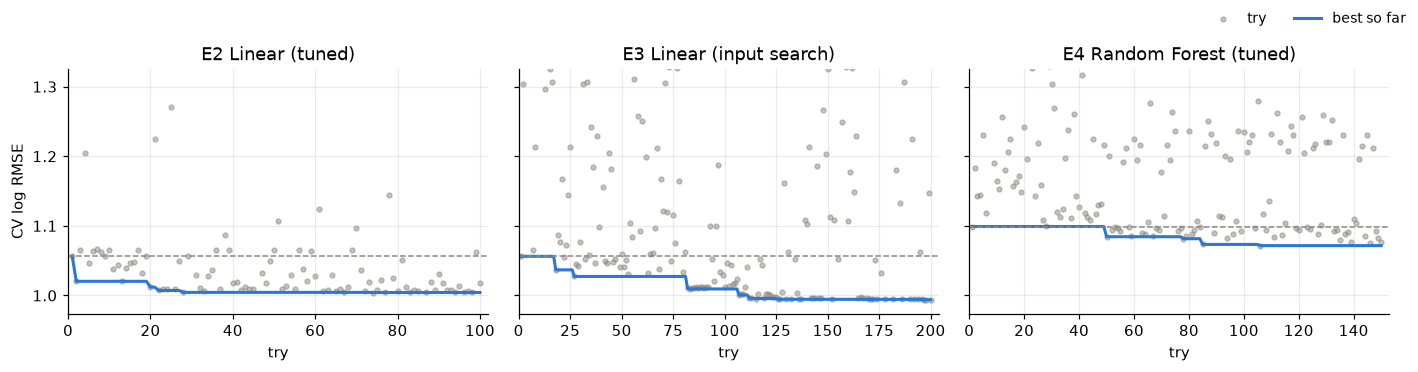

In [10]:
studies = {"E2 Linear (tuned)": linear_study, "E3 Linear (input search)": inputs_study,
           "E4 Random Forest (tuned)": rf_study}
all_errors = [t.value for s in studies.values() for t in s.trials]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, (name, study) in zip(axes, studies.items()):
    errors = np.array([t.value for t in study.trials])
    tries = np.arange(1, len(errors) + 1)
    ax.scatter(tries, errors, s=10, color=GRAY, alpha=0.5, label="try")
    ax.plot(tries, np.minimum.accumulate(errors), color=BLUE, lw=2, label="best so far")
    ax.axhline(errors[0], ls="--", color=GRAY, lw=1)
    ax.set(title=name, xlabel="try", xlim=(0, len(errors) * 1.02))
axes[0].set_ylabel("CV log RMSE")
axes[0].set_ylim(min(all_errors) - 0.02, np.quantile(all_errors, 0.9))
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2, frameon=False, fontsize=9)
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

## Results

Refit the tuned settings on all training rows -> score on val.

In [11]:
for name, p in [("E2 Linear (tuned)", best_linear), ("E3 Linear (input search)", best_inputs)]:
    cols = linear_columns(p)
    model = linear_model(p).fit(XL_train[cols], log_y_train)
    record(name, np.expm1(model.predict(XL_val[cols])))

tuned_rf = rf_model(best_rf).fit(X_train, log_y_train)
record("E4 Random Forest (tuned)", np.expm1(tuned_rf.predict(X_val)))

score()

,R2,log R2,MAPE (%),typical factor off,within 2x (%)
model,,,,,
E0 overall median,-0.14,-0.07,766.68,5.13,16.25
E0 product median,-0.13,-0.02,693.83,5.15,20.00
E1 Ridge (Abhiram),0.42,0.38,106.50,1.99,50.00
E1 Random Forest (Bakari),0.56,0.35,107.02,1.87,53.75
E1 XGBoost (Bakari),0.42,0.38,124.67,1.80,58.75
E2 Linear (tuned),0.61,0.37,105.34,1.92,51.25
E3 Linear (input search),-0.39,0.33,120.73,2.23,43.75
E4 Random Forest (tuned),0.62,0.39,97.87,1.89,53.75


## Compare

Gray = teammates' settings, blue = tuned. Dashed = brief's goal. Baselines left out (MAPE ~700%).

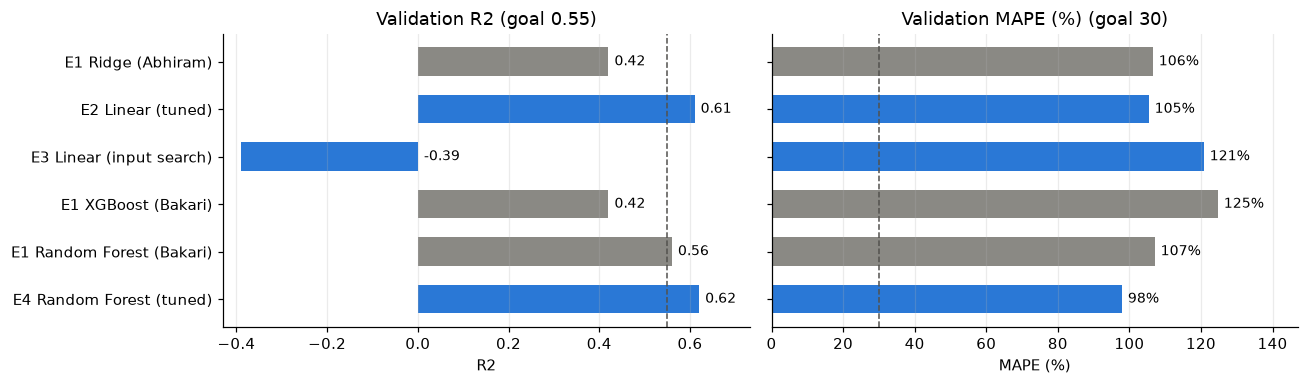

In [12]:
models = ["E1 Ridge (Abhiram)", "E2 Linear (tuned)", "E3 Linear (input search)",
          "E1 XGBoost (Bakari)", "E1 Random Forest (Bakari)", "E4 Random Forest (tuned)"]
tuned = ["E2 Linear (tuned)", "E3 Linear (input search)", "E4 Random Forest (tuned)"]
colors = [BLUE if m in tuned else GRAY for m in models]
table = score()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, metric in zip(axes, ["R2", "MAPE (%)"]):
    values = table.loc[models, metric]
    ax.barh(models, values, color=colors, height=0.6)
    ax.axvline(GOAL[metric], ls="--", color=INK, lw=1)
    for y, v in enumerate(values):
        ax.annotate(f"{v:.2f}" if metric == "R2" else f"{v:.0f}%", (max(v, 0), y),
                    xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
    ax.set_xlim(min(0, values.min() * 1.1), max(values.max(), GOAL[metric]) * 1.18)
    ax.set(title=f"Validation {metric} (goal {GOAL[metric]:g})", xlabel=metric)
    ax.grid(axis="y", visible=False)
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

### Predicted vs actual

Dashed line = perfect. Shaded band = within 2x. The 2 campaigns under $1k are left out.

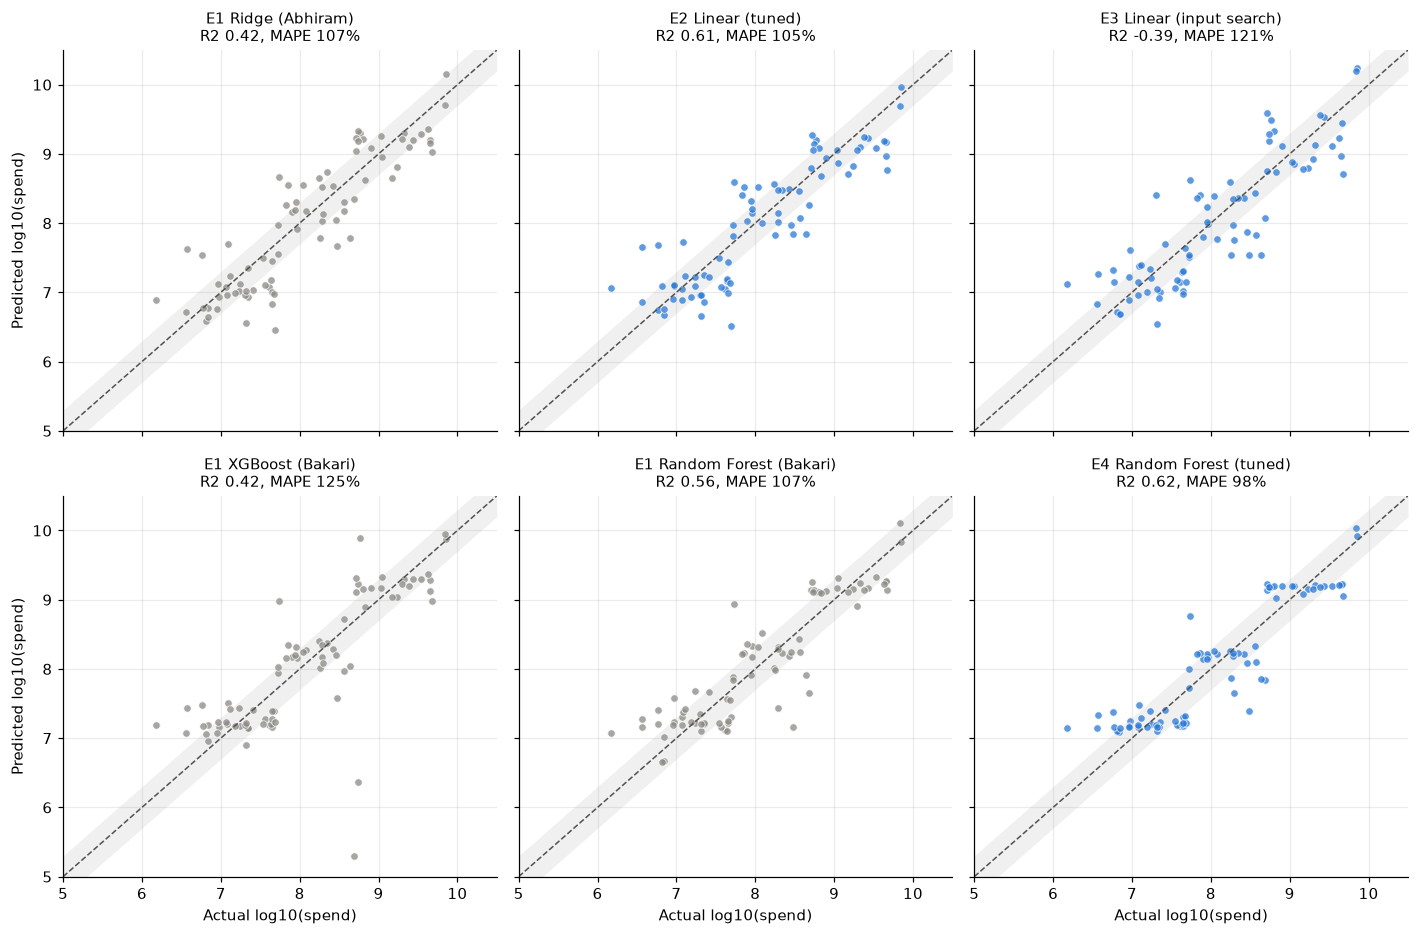

In [13]:
shown = y_val.to_numpy() >= MAPE_MIN_SPEND
actual = np.log10(y_val.to_numpy()[shown])
low, high = 5, 10.5

fig, axes = plt.subplots(2, 3, figsize=(13, 8.6), sharex=True, sharey=True)
for ax, name in zip(axes.flat, models):
    predicted = np.log10(1 + predictions[name][shown])
    ax.fill_between([low, high], [low - np.log10(2), high - np.log10(2)], [low + np.log10(2), high + np.log10(2)],
                    color=GRAY, alpha=0.12, lw=0)
    ax.plot([low, high], [low, high], "--", color=INK, lw=1)
    ax.scatter(actual, predicted, s=24, alpha=0.75, color=BLUE if name in tuned else GRAY,
               edgecolor="white", linewidth=0.6)
    ax.set_title(f"{name}\nR2 {results[name]['R2']:.2f}, MAPE {results[name]['MAPE (%)']:.0f}%", fontsize=9.5)
    ax.set(xlim=(low, high), ylim=(low, high))
for ax in axes[1]:
    ax.set_xlabel("Actual log10(spend)")
for ax in axes[:, 0]:
    ax.set_ylabel("Predicted log10(spend)")
plt.tight_layout()
plt.show()

### Why E3 does worse

Best CV score of anything, but negative R² on val. R² in $ is driven by the biggest campaigns -> E3 over-predicts the two ~$7B ones by 2x+.

In [14]:
# E3's biggest $ misses, next to E2 on the same campaigns
misses = pd.DataFrame({"product": product_of(X_val).str.replace("sub_product_name_", ""),
                       "actual ($M)": y_val / 1e6,
                       "E2 ($M)": predictions["E2 Linear (tuned)"] / 1e6,
                       "E3 ($M)": predictions["E3 Linear (input search)"] / 1e6})
squared_error = (misses["E3 ($M)"] - misses["actual ($M)"]) ** 2
print(f"Top 3 campaigns = {squared_error.nlargest(3).sum() / squared_error.sum():.0%} of E3's squared $ error")
misses.loc[squared_error.nlargest(5).index].round(0)

Top 3 campaigns = 77% of E3's squared $ error


,product,actual ($M),E2 ($M),E3 ($M)
3,EMAIL ALERT,7130.0,9411.0,17199.0
48,BRAND ALERT,6899.0,4898.0,15572.0
28,EMAIL ALERT,4724.0,585.0,518.0
33,EMAIL ALERT,4528.0,940.0,942.0
47,BRAND ALERT,519.0,1847.0,3856.0


### MAPE by campaign size

Val MAPE (%) by spend range. Small campaigns = most of the % error.

In [15]:
ranges = pd.cut(y_val, [MAPE_MIN_SPEND, 1e8, 1e9, np.inf], right=False, labels=["$1k-$100M", "$100M-$1B", "$1B+"])
print("Validation rows:", ranges.value_counts(sort=False).to_dict())

by_range = {}
for name in models:
    by_range[name] = {}
    for r in ranges.cat.categories:
        rows = (ranges == r).to_numpy()
        by_range[name][r] = evaluate(y_val[rows], predictions[name][rows])["MAPE (%)"]
pd.DataFrame(by_range).T.rename_axis("model").round(0)

Validation rows: {'$1k-$100M': 42, '$100M-$1B': 23, '$1B+': 15}


,$1k-$100M,$100M-$1B,$1B+
model,,,
E1 Ridge (Abhiram),125.0,108.0,51.0
E2 Linear (tuned),140.0,78.0,49.0
E3 Linear (input search),140.0,123.0,63.0
E1 XGBoost (Bakari),152.0,130.0,40.0
E1 Random Forest (Bakari),140.0,86.0,46.0
E4 Random Forest (tuned),124.0,86.0,43.0


---
# Report

| Experiment | R² | MAPE | Within 2x | Takeaway |
|---|---|---|---|---|
| E0 overall median | −0.14 | 767% | 16% | floor |
| E0 product median | −0.13 | 694% | 20% | product alone barely helps |
| E1 Ridge (Abhiram) | 0.42 | 106.5% | 50% | starting point for linear |
| E1 Random Forest (Bakari) | 0.56 | 107.0% | 54% | starting point for RF |
| E1 XGBoost (Bakari) | 0.42 | 124.7% | 59% | not tuned, reference only |
| E2 Linear (tuned) | 0.61 | 105.3% | 51% | R² up a lot; ends up almost pure Lasso on the same 14 columns |
| E3 Linear (input search) | −0.39 | 120.7% | 44% | best CV but worst val -> picking inputs overfit the folds |
| E4 Random Forest (tuned) | 0.62 | 97.9% | 54% | best overall; smaller trees (depth 4, 58% of rows per tree) |

- **Brief goal:** R² above 0.55 is met by both tuned models (E2 0.61, E4 0.62). MAPE under 30% isn't met by anything (best 98%).
- **Tuning helps R², not MAPE:** MAPE only dropped 1–9 points. Models are still ~1.9x off on a typical campaign -> target list + product + size explain how big a campaign is, not why same-product campaigns spend different amounts.
- **Small campaigns drive MAPE:** 124–152% on $1k–$100M campaigns vs 40–63% on $1B+.
- **More search ≠ better:** E3 kept only target list × product -> over-predicted the two ~$7B campaigns by 2x+. 332 rows isn't enough to choose between 512 input combos.
- **Caveat:** this val set has been used across several of our notebooks -> numbers are optimistic. Still need a real H2 test.
- **Next:** handle the 6 training campaigns under $1k, try a log -> $ correction (Duan smearing), find inputs that explain spend within a product.